# Molecular Graph Creation: With and Without Virtual Nodes

This notebook demonstrates how molecular graphs are created using the graphamole library, comparing standard molecular graphs with graphs that include virtual nodes for representing adducts or other molecular context.

## 1. Import Required Libraries

In [1]:
import sys

sys.path.insert(0, "/mnt/c/Users/robbe/Work/Waters_GNN_SmalMol")

import numpy as np
import torch
from rdkit import Chem
from rdkit.Chem import Draw
import matplotlib.pyplot as plt
import networkx as nx


from graphamole.featurizers import ALL_FEATURIZERS
from GraphXSection_torch.adduct_features import AdductFeatureExtractor
from GraphXSection_torch.data_extract import MoleculeIon

print("Libraries imported successfully!")
print(f"PyTorch version: {torch.__version__}")

Libraries imported successfully!
PyTorch version: 2.8.0+cu128


## 2. Initialize Featurizer and Adduct Feature Extractor

We'll use the standard featurizer collection and set up the adduct feature extractor that will be used for the virtual node.

In [2]:
# Initialize the collection of atom featurizers
featurizers = ALL_FEATURIZERS

# Initialize the adduct feature extractor for virtual nodes
adduct_extractor = AdductFeatureExtractor()

## 3. Create Example Molecule

Let's create a simple molecule (ethanol) to demonstrate graph creation. We'll also specify an adduct type.

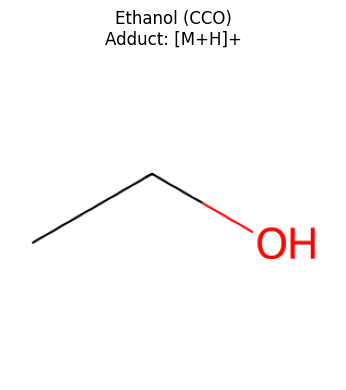

Molecule: CCO
Number of atoms: 3
Number of bonds: 2
Adduct: [M+H]+
CCS: 150.5 Ų


In [3]:
# Create ethanol molecule
smiles = "CCO"
adduct = "[M+H]+"
ccs_value = 150.5  # Example CCS value

# Create RDKit mol object
rdkit_mol = Chem.MolFromSmiles(smiles)

# Display molecule structure
img = Draw.MolToImage(rdkit_mol, size=(300, 300))
plt.figure(figsize=(4, 4))
plt.imshow(img)
plt.axis("off")
plt.title(f"Ethanol ({smiles})\nAdduct: {adduct}")
plt.tight_layout()
plt.show()

print(f"Molecule: {smiles}")
print(f"Number of atoms: {rdkit_mol.GetNumAtoms()}")
print(f"Number of bonds: {rdkit_mol.GetNumBonds()}")
print(f"Adduct: {adduct}")
print(f"CCS: {ccs_value} Ų")

## 4. Create Graph WITHOUT Virtual Node

First, let's create a standard molecular graph without a virtual node. Adduct information will be encoded as global features.

In [ ]:
# Create MoleculeIon object without virtual node
mol_no_vnode = MoleculeIon(input_smiles=smiles, adduct=adduct)

# Get the PyG Data object
data_no_vnode = mol_no_vnode.get_data(
    featurizer_collection=featurizers, one_hot_encode=False, add_virtual_node=False
)

print("=== Graph WITHOUT Virtual Node ===")
print(f"\nNode features (x_atoms):")
print(f"  Shape: {data_no_vnode.x_atoms.shape}")
print(f"  Type: {data_no_vnode.x_atoms.dtype}")
print(
    f"  First atom features: {data_no_vnode.x_atoms[0][:5].tolist()}... (showing first 5)"
)
print(f"  Length of node features: {data_no_vnode.x_atoms.shape[1]}")

print(f"\nEdge index:")
print(f"  Shape: {data_no_vnode.edge_index.shape}")
print(f"  Number of edges: {data_no_vnode.edge_index.shape[1]}")
print(f"  Edge index:\n{data_no_vnode.edge_index}")

print(f"\nEdge features (edge_attr):")
print(f"  Shape: {data_no_vnode.edge_attr.shape}")

print(f"\nNode types:")
print(f"  Shape: {data_no_vnode.node_types.shape}")
print(f"  Values: {data_no_vnode.node_types.tolist()}")
print(f"  (all zeros = all atoms)")

print(f"\nGlobal features:")
print(f"  Present: {hasattr(data_no_vnode, 'global_feats')}")
if hasattr(data_no_vnode, "global_feats"):
    print(
        f"  Shape: {data_no_vnode.global_feats.shape if data_no_vnode.global_feats is not None else 'None'}"
    )

print(f"\nHas virtual node: {data_no_vnode.has_virtual_node}")

=== Graph WITHOUT Virtual Node ===

Node features (x_atoms):
  Shape: torch.Size([3, 15])
  Type: torch.int64
  First atom features: [15, 3, 0, 3, 3]... (showing first 5)
  Length of node features: 15

Edge index:
  Shape: torch.Size([2, 4])
  Number of edges: 4
  Edge index:
tensor([[0, 1, 1, 2],
        [1, 0, 2, 1]])

Edge features (edge_attr):
  Shape: torch.Size([4, 4])

Node types:
  Shape: torch.Size([3])
  Values: [0, 0, 0]
  (all zeros = all atoms)

Global features:
  Present: False

Has virtual node: False


## 5. Create Graph WITH Virtual Node

Now let's create the same molecule with a virtual node. The virtual node will represent the adduct and connect to all atoms.

In [ ]:
# Create MoleculeIon object WITH virtual node
mol_with_vnode = MoleculeIon(input_smiles=smiles, adduct=adduct)

# Extract adduct features for the virtual node
virtual_node_features = adduct_extractor.extract_features(adduct)
adduct_dim = len(virtual_node_features)

# Get the PyG Data object with virtual node
data_with_vnode = mol_with_vnode.get_data(
    featurizer_collection=featurizers,
    one_hot_encode=False,
    add_virtual_node=True,
    virtual_node_features=virtual_node_features,
)

print("=== Graph WITH Virtual Node ===")
print(f"\nAtom features (x_atoms):")
print(f"  Shape: {data_with_vnode.x_atoms.shape}")
print(f"  Type: {data_with_vnode.x_atoms.dtype}")
print(
    f"  First atom features: {data_with_vnode.x_atoms[0][:5].tolist()}... (showing first 5)"
)
print(f"  Length of node features: {data_with_vnode.x_atoms.shape[1]}")

print(f"\nVirtual node features (x_vnode):")
print(f"  Shape: {data_with_vnode.x_vnode.shape}")
print(f"  Type: {data_with_vnode.x_vnode.dtype}")
print(
    f"  Values: {data_with_vnode.x_vnode[0][:5].tolist()}... (showing first 5 of {adduct_dim} features)"
)
print(f"  Length of virtual node features: {data_with_vnode.x_vnode.shape[1]}")

print(f"\nNode types:")
print(f"  Shape: {data_with_vnode.node_types.shape}")
print(f"  Values: {data_with_vnode.node_types.tolist()}")
print(f"  (0 = atom, 1 = virtual node)")

print(f"\nEdge index:")
print(f"  Shape: {data_with_vnode.edge_index.shape}")
print(f"  Number of edges: {data_with_vnode.edge_index.shape[1]}")

print(f"\nEdge types:")
print(f"  Shape: {data_with_vnode.edge_types.shape}")
print(f"  Values: {data_with_vnode.edge_types.tolist()}")
print(f"  (0 = bond edge, 1 = virtual node edge)")

print(f"\nEdge features (edge_attr):")
print(f"  Shape: {data_with_vnode.edge_attr.shape}")

print(f"\nGlobal features:")
print(f"  Present: {hasattr(data_with_vnode, 'global_feats')}")
if hasattr(data_with_vnode, "global_feats"):
    print(
        f"  Shape: {data_with_vnode.global_feats.shape if data_with_vnode.global_feats is not None else 'None'}"
    )

print(f"\nVirtual node index:")
print(f"  Value: {data_with_vnode.virtual_node_idx}")

=== Graph WITH Virtual Node ===

Atom features (x_atoms):
  Shape: torch.Size([3, 15])
  Type: torch.int64
  First atom features: [15, 3, 0, 3, 3]... (showing first 5)
  Length of node features: 15

Virtual node features (x_vnode):
  Shape: torch.Size([1, 16])
  Type: torch.float32
  Values: [0.0, 0.0, 1.0, 1.0, 0.0]... (showing first 5 of 16 features)
  Length of virtual node features: 16

Node types:
  Shape: torch.Size([4])
  Values: [0, 0, 0, 1]
  (0 = atom, 1 = virtual node)

Edge index:
  Shape: torch.Size([2, 10])
  Number of edges: 10

Edge types:
  Shape: torch.Size([10])
  Values: [0, 0, 0, 0, 1, 1, 1, 1, 1, 1]
  (0 = bond edge, 1 = virtual node edge)

Edge features (edge_attr):
  Shape: torch.Size([10, 5])

Global features:
  Present: False

Virtual node index:
  Value: 3


## 6. Compare Graph Structures

Let's compare the key differences between the two representations:

In [10]:
import pandas as pd

# Create comparison table
comparison_data = {
    "Property": [
        "Number of nodes",
        "Number of edges",
        "Atom feature shape",
        "Virtual node feature shape",
        "Edge types present",
        "Adduct encoding",
        "Global features used",
    ],
    "Without Virtual Node": [
        data_no_vnode.x_atoms.shape[0],
        data_no_vnode.edge_index.shape[1],
        str(data_no_vnode.x_atoms.shape),
        "N/A",
        "Bond edges only",
        "Global feature vector",
        "Yes",
    ],
    "With Virtual Node": [
        data_with_vnode.x_atoms.shape[0] + 1,  # atoms + 1 virtual node
        data_with_vnode.edge_index.shape[1],
        str(data_with_vnode.x_atoms.shape),
        str(data_with_vnode.x_vnode.shape),
        "Bond + Virtual node edges",
        "Virtual node features",
        "No",
    ],
}

df_comparison = pd.DataFrame(comparison_data)
print(df_comparison.to_string(index=False))

print("\n" + "=" * 60)
print("KEY DIFFERENCES:")
print("=" * 60)
print(
    f"1. Nodes: {data_no_vnode.x_atoms.shape[0]} atoms → {data_with_vnode.x_atoms.shape[0]} atoms + 1 virtual node"
)
print(
    f"2. Edges: {data_no_vnode.edge_index.shape[1]} → {data_with_vnode.edge_index.shape[1]} (added {data_with_vnode.edge_index.shape[1] - data_no_vnode.edge_index.shape[1]} virtual node edges)"
)
print(
    f"3. Adduct info: No virtual node ({data_no_vnode.x_atoms.shape[0]} atoms only) → Virtual node ({data_with_vnode.x_vnode.shape[1]} dims)"
)
print(f"4. Node types: Single type → 2 types (atom=0, virtual=1)")
print(f"5. Edge types: Single type → 2 types (bond=0, virtual=1)")

                  Property  Without Virtual Node         With Virtual Node
           Number of nodes                     3                         4
           Number of edges                     4                        10
        Atom feature shape   torch.Size([3, 15])       torch.Size([3, 15])
Virtual node feature shape                   N/A       torch.Size([1, 16])
        Edge types present       Bond edges only Bond + Virtual node edges
           Adduct encoding Global feature vector     Virtual node features
      Global features used                   Yes                        No

KEY DIFFERENCES:
1. Nodes: 3 atoms → 3 atoms + 1 virtual node
2. Edges: 4 → 10 (added 6 virtual node edges)
3. Adduct info: No virtual node (3 atoms only) → Virtual node (16 dims)
4. Node types: Single type → 2 types (atom=0, virtual=1)
5. Edge types: Single type → 2 types (bond=0, virtual=1)


## 7. Visualize Edge Connectivity

Let's examine exactly which edges were added for the virtual node:

In [11]:
# Separate edges by type
edge_index = data_with_vnode.edge_index
edge_types = data_with_vnode.edge_types

bond_edges = edge_index[:, edge_types == 0]
vnode_edges = edge_index[:, edge_types == 1]

print("Bond Edges (atom-atom connections):")
print(f"  Shape: {bond_edges.shape}")
print(f"  Edges: {bond_edges.t().tolist()}")

print("\nVirtual Node Edges (virtual node-atom connections):")
print(f"  Shape: {vnode_edges.shape}")
print(f"  Edges: {vnode_edges.t().tolist()}")

print(f"\nVirtual node index: {data_with_vnode.virtual_node_idx}")
print(
    f"Virtual node connects to atoms: {sorted(set(vnode_edges[1].tolist() + vnode_edges[0].tolist()) - {data_with_vnode.virtual_node_idx})}"
)

# Verify bidirectional connectivity
num_atoms = data_with_vnode.x_atoms.shape[0]
expected_vnode_edges = num_atoms * 2  # Each atom connects to vnode in both directions
actual_vnode_edges = vnode_edges.shape[1]
print(f"\nExpected virtual node edges: {expected_vnode_edges} (2 × {num_atoms} atoms)")
print(f"Actual virtual node edges: {actual_vnode_edges}")
print(f"✓ Match!" if expected_vnode_edges == actual_vnode_edges else "✗ Mismatch!")

Bond Edges (atom-atom connections):
  Shape: torch.Size([2, 4])
  Edges: [[0, 1], [1, 0], [1, 2], [2, 1]]

Virtual Node Edges (virtual node-atom connections):
  Shape: torch.Size([2, 6])
  Edges: [[3, 0], [0, 3], [3, 1], [1, 3], [3, 2], [2, 3]]

Virtual node index: 3
Virtual node connects to atoms: [0, 1, 2]

Expected virtual node edges: 6 (2 × 3 atoms)
Actual virtual node edges: 6
✓ Match!


## 8. Visualize Graph Structure with NetworkX

Create network visualizations to see the difference visually:

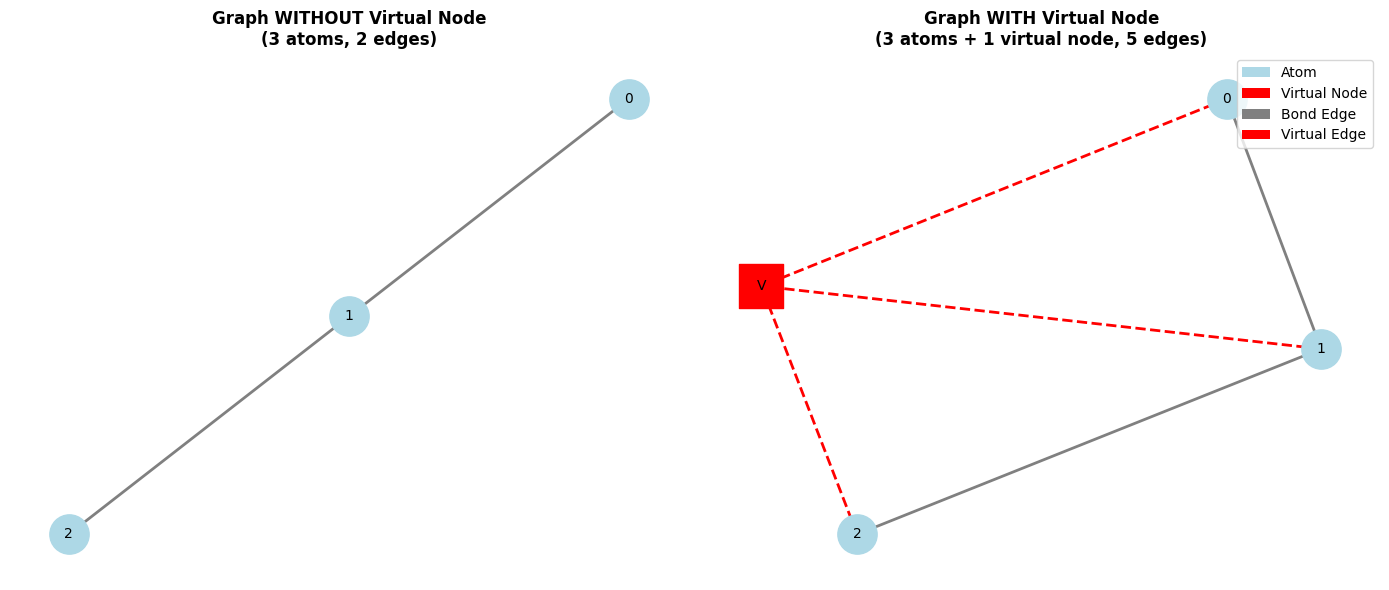

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# ===== Plot 1: Without Virtual Node =====
ax = axes[0]
G_no_vnode = nx.Graph()

# Add nodes
for i in range(data_no_vnode.x_atoms.shape[0]):
    G_no_vnode.add_node(i, label=f"Atom {i}")

# Add edges
edge_list = data_no_vnode.edge_index.t().tolist()
G_no_vnode.add_edges_from([(u, v) for u, v in edge_list if u < v])  # Avoid duplicates

pos = nx.spring_layout(G_no_vnode, seed=42)
nx.draw_networkx_nodes(G_no_vnode, pos, node_color="lightblue", node_size=800, ax=ax)
nx.draw_networkx_edges(G_no_vnode, pos, edge_color="gray", width=2, ax=ax)
nx.draw_networkx_labels(
    G_no_vnode, pos, labels={i: f"{i}" for i in G_no_vnode.nodes()}, font_size=10, ax=ax
)
ax.set_title(
    f"Graph WITHOUT Virtual Node\n({rdkit_mol.GetNumAtoms()} atoms, {G_no_vnode.number_of_edges()} edges)",
    fontsize=12,
    fontweight="bold",
)
ax.axis("off")

# ===== Plot 2: With Virtual Node =====
ax = axes[1]
G_with_vnode = nx.Graph()

# Add atom nodes
num_atoms = data_with_vnode.x_atoms.shape[0]
for i in range(num_atoms):
    G_with_vnode.add_node(i, label=f"Atom {i}", node_type="atom")

# Add virtual node
vnode_idx = data_with_vnode.virtual_node_idx
G_with_vnode.add_node(vnode_idx, label="VNode", node_type="virtual")

# Add edges
edge_index = data_with_vnode.edge_index
edge_types = data_with_vnode.edge_types
for i in range(edge_index.shape[1]):
    u, v = edge_index[0, i].item(), edge_index[1, i].item()
    if u < v or (
        u == vnode_idx or v == vnode_idx
    ):  # Avoid duplicates, include vnode edges
        edge_type = "virtual" if edge_types[i].item() == 1 else "bond"
        G_with_vnode.add_edge(u, v, edge_type=edge_type)

# Position nodes
pos = nx.spring_layout(G_with_vnode, seed=42)

# Draw atom nodes
atom_nodes = [
    n for n, attr in G_with_vnode.nodes(data=True) if attr["node_type"] == "atom"
]
nx.draw_networkx_nodes(
    G_with_vnode, pos, nodelist=atom_nodes, node_color="lightblue", node_size=800, ax=ax
)

# Draw virtual node
nx.draw_networkx_nodes(
    G_with_vnode,
    pos,
    nodelist=[vnode_idx],
    node_color="red",
    node_size=1000,
    node_shape="s",
    ax=ax,
)  # Square shape

# Draw bond edges
bond_edges = [
    (u, v)
    for u, v, attr in G_with_vnode.edges(data=True)
    if attr["edge_type"] == "bond"
]
nx.draw_networkx_edges(
    G_with_vnode, pos, edgelist=bond_edges, edge_color="gray", width=2, ax=ax
)

# Draw virtual node edges
vnode_edges_list = [
    (u, v)
    for u, v, attr in G_with_vnode.edges(data=True)
    if attr["edge_type"] == "virtual"
]
nx.draw_networkx_edges(
    G_with_vnode,
    pos,
    edgelist=vnode_edges_list,
    edge_color="red",
    width=2,
    style="dashed",
    ax=ax,
)

# Labels
labels = {i: f"{i}" if i != vnode_idx else "V" for i in G_with_vnode.nodes()}
nx.draw_networkx_labels(G_with_vnode, pos, labels=labels, font_size=10, ax=ax)

ax.set_title(
    f"Graph WITH Virtual Node\n({num_atoms} atoms + 1 virtual node, {G_with_vnode.number_of_edges()} edges)",
    fontsize=12,
    fontweight="bold",
)
ax.axis("off")

# Add legend
from matplotlib.patches import Patch

legend_elements = [
    Patch(facecolor="lightblue", label="Atom"),
    Patch(facecolor="red", label="Virtual Node"),
    Patch(facecolor="gray", label="Bond Edge"),
    Patch(facecolor="red", label="Virtual Edge"),
]
axes[1].legend(handles=legend_elements, loc="upper right")

plt.tight_layout()
plt.show()

## 9. Understanding PyTorch Geometric Batching

When multiple graphs are batched together in PyTorch Geometric, the virtual node structure is preserved:

In [ ]:
from torch_geometric.data import Batch

# Create a second molecule for batching
smiles2 = "C"  # Methane
adduct2 = "[M+Na]+"
ccs2 = 120.0

mol2 = MoleculeIon(
    input_smiles=smiles2,
    adduct=adduct2,
)

data2 = mol2.get_data(
    featurizer_collection=featurizers,
    add_virtual_node=True,
    virtual_node_features=adduct_extractor.extract_features(adduct2),
)

# Create a batch
batch = Batch.from_data_list([data_with_vnode, data2])

print("=== Batched Graphs ===")
print(f"\nBatch size: {batch.num_graphs}")
print(f"\nTotal atoms in batch: {batch.x_atoms.shape[0]}")
print(f"  Graph 1: {data_with_vnode.x_atoms.shape[0]} atoms")
print(f"  Graph 2: {data2.x_atoms.shape[0]} atoms")

print(f"\nTotal virtual nodes in batch: {batch.x_vnode.shape[0]}")
print(f"  (1 virtual node per graph)")

print(f"\nVirtual node features shape: {batch.x_vnode.shape}")
print(f"  Each row corresponds to one graph's virtual node")

print(f"\nNode types shape: {batch.node_types.shape}")
print(f"  Total nodes (atoms + vnodes): {batch.node_types.shape[0]}")

print(f"\nEdge index shape: {batch.edge_index.shape}")
print(f"  Total edges: {batch.edge_index.shape[1]}")

print(f"\nBatch vector (for atoms):")
if hasattr(batch, "x_atoms_batch"):
    print(f"  Shape: {batch.x_atoms_batch.shape}")
    print(f"  Values: {batch.x_atoms_batch.tolist()}")
    print(f"  Indicates which graph each atom belongs to")
elif hasattr(batch, "batch"):
    print(f"  Shape: {batch.batch.shape}")
    print(f"  Values: {batch.batch.tolist()}")

print("\n" + "=" * 60)
print("KEY INSIGHT: PyTorch Geometric batches x_atoms and x_vnode")
print("separately, preserving the structure:")
print("  - x_atoms: concatenated atom features from all graphs")
print("  - x_vnode: one row per graph (not concatenated with atoms)")
print("  - node_types: indicates atom (0) vs virtual node (1)")
print("  - edge_types: indicates bond (0) vs virtual edge (1)")
print("=" * 60)

=== Batched Graphs ===

Batch size: 2

Total atoms in batch: 4
  Graph 1: 3 atoms
  Graph 2: 1 atoms

Total virtual nodes in batch: 2
  (1 virtual node per graph)

Virtual node features shape: torch.Size([2, 16])
  Each row corresponds to one graph's virtual node

Node types shape: torch.Size([6])
  Total nodes (atoms + vnodes): 6

Edge index shape: torch.Size([2, 12])
  Total edges: 12

Batch vector (for atoms):
  Shape: torch.Size([2])
  Values: [0, 1]

KEY INSIGHT: PyTorch Geometric batches x_atoms and x_vnode
separately, preserving the structure:
  - x_atoms: concatenated atom features from all graphs
  - x_vnode: one row per graph (not concatenated with atoms)
  - node_types: indicates atom (0) vs virtual node (1)
  - edge_types: indicates bond (0) vs virtual edge (1)


## 10. Summary: Design Principles

**Why Virtual Nodes?**

1. **Explicit Adduct Representation**: Virtual node allows the model to learn direct interactions between adduct information and molecular atoms through message passing.

2. **Architectural Consistency**: All information flows through graph convolutions rather than mixing convolutional and global feature processing.

3. **Attention Mechanism**: VirtualNodeAttention layer enables the model to learn which atoms are most influenced by the adduct.

**Key Implementation Details:**

- Virtual node index = `num_atoms` (always the last node)
- Bidirectional edges connect virtual node to all atoms
- Separate encoders: categorical embeddings for atoms, MLP for virtual node
- Edge types distinguish bond edges (0) from virtual edges (1)
- During pooling, only atom nodes are aggregated (virtual node excluded)

**Trade-offs:**

- ✅ More expressive: Adduct-atom interactions learned via GNN layers
- ✅ Better for complex adducts: Direct feature learning vs. fixed encoding
- ✅ Attention interpretability: Can visualize adduct-atom attention weights
- ⚠️ More parameters: Separate encoder and attention mechanism
- ⚠️ More edges: 2N additional edges (N = number of atoms)

## 11. Next Steps

To train a model with virtual nodes:

```bash
# Activate environment
pyenv activate GXS_torch

# Run training
python -m GraphXSection_torch configs/sigma_adduct_vnode_config.json --use-lightning
```

**Config Requirements:**
- `use_adduct_virtual_node: true`
- `adduct_feature_dim: <dimension>` (from AdductFeatureExtractor)

**Model Modifications:**
- Separate encoders for atoms and virtual nodes
- VirtualNodeAttention layer after ECC layers
- Pooling excludes virtual nodes
- Dense head input = ECC output only (no global features)